<a href="https://colab.research.google.com/github/Divya4325/Cleaned-Banana-Classification-Detection/blob/main/04_Yolo_detection_counting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!ls "/content/drive/MyDrive"

 Clean_Banana_dataset.zip
 clustering_feature_names.pkl
 cluster_map.pkl
'Colab Notebooks'
'Copy of Clean_Banana_dataset.zip'
'Copy of Copy of Forest_Cover.csv'
'Copy of Forest_Cover.csv'
 diamond_pipeline.pkl
 diamonds.csv
 Divya_Authorization_AR_Resume.pdf
 encoder_cluster.pkl
 features_diamond.pkl
 features.pkl
'Final Project DS-S-WE-T-B116&DS-S-WE-T-B123.gdoc'
 Forest_Cover.csv
 imputer.pkl
 kmeans_model.pkl
 Letter.gdoc
 model_final_feature.pkl
 onehotencoder_diamond.pkl
 onehot_encoder.pkl
 ordinalencoder_diamond.pkl
 Resume.gdoc
 rf_final.pkl
 scale.pkl
 scaler_cluster.pkl
 scaler_diamond.pkl
 scaler_feature.pkl
 scaler.pkl
 target_encoder.pkl
 xgb_diamond.pkl
 xgb_final.pkl
 xgb_model.pkl
'Yolo Project.v1i.yolov8.zip'


In [ ]:
!unzip "/content/drive/MyDrive/Yolo Project.v1i.yolov8.zip"

Archive:  /content/drive/MyDrive/Yolo Project.v1i.yolov8.zip
 extracting: train/images/musa-acuminata-banana-b3b229f9-394a-11ec-bd6e-d8c4975e38aa_jpg.rf.22a811385045eecf6ca48fe0b6fcc756.jpg  
 extracting: train/images/musa-acuminata-freshunripe-2edfeb7e-2653-11ec-b6fb-d8c4975e38aa_jpg.rf.668337742d462ac4c3783488b61388fa.jpg  
 extracting: train/images/musa-acuminata-banana-9aabbca9-394a-11ec-8bda-d8c4975e38aa_jpg.rf.f91b6563293424e6b48b8e23b28a297c.jpg  
 extracting: train/images/musa-acuminata-freshunripe-2c3640ac-2653-11ec-9d59-d8c4975e38aa_jpg.rf.289f58c28596f204a37273a08ad13b4b.jpg  
 extracting: train/images/musa-acuminata-banana-c4b432aa-394a-11ec-901f-d8c4975e38aa_jpg.rf.0067ea117ab7408ccf52ab86a0324bd8.jpg  
 extracting: train/images/musa-acuminata-mold-e3dc13ee-1d0a-11ec-91aa-d8c4975e38aa_jpg.rf.4e1fa44101d57f39910fd3551752d5e1.jpg  
 extracting: train/images/musa-acuminata-mold-e1d47dce-1d0a-11ec-a1ed-d8c4975e38aa_jpg.rf.80d572c4f93ddf362bc9b5fa13498fe4.jpg  
 extracting: tra

In [ ]:
!find /content -name "data.yaml"

/content/data.yaml


# **YOLO Object Detection**

In [ ]:
! pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.1/42.1 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 49.9 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
model = YOLO("yolov8n.pt")

In [ ]:
#Train the model
results = model.train(
    data = "/content/data.yaml",
    epochs = 50,
    imgsz = 416,
    batch = 16,
    patience =10
)

Ultralytics 8.4.92 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patienc

In [ ]:
!ls /content/runs/detect/train/weights/


best.pt  last.pt


In [ ]:
from google.colab import files  #Don't run this again becoz model saved locally
files.download("/content/runs/detect/train/weights/best.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Predict on test image
model = YOLO("/content/runs/detect/train/weights/best.pt")
results = model.predict(
    source = "/content/test/images",
    save = True,
    conf = 0.25
)


image 1/88 /content/test/images/musa-acuminata-banana-8b4f22e4-394a-11ec-9d08-d8c4975e38aa_jpg.rf.525ac85c7ba8db70ab8caafd4c6f3969.jpg: 416x416 1 Banana, 9.6ms
image 2/88 /content/test/images/musa-acuminata-banana-8b6bc840-394a-11ec-b09c-d8c4975e38aa_jpg.rf.f19ff8f51c08553750cd1329ef5bb8d3.jpg: 416x416 1 Banana, 8.3ms
image 3/88 /content/test/images/musa-acuminata-banana-8b71ff0b-394a-11ec-ab9a-d8c4975e38aa_jpg.rf.dca71055ee7207e22b40b87c37565923.jpg: 416x416 1 Banana, 6.2ms
image 4/88 /content/test/images/musa-acuminata-banana-8baeeab1-394a-11ec-84c0-d8c4975e38aa_jpg.rf.971f91660d6dab02466c105045b02ce4.jpg: 416x416 1 Banana, 6.3ms
image 5/88 /content/test/images/musa-acuminata-banana-8beffea0-394a-11ec-b5ec-d8c4975e38aa_jpg.rf.2ce444f02b331f9736a6411f368a7e7e.jpg: 416x416 1 Banana, 5.7ms
image 6/88 /content/test/images/musa-acuminata-banana-8bf60ec7-394a-11ec-94b9-d8c4975e38aa_jpg.rf.8d523361ced7fc376a361289f0969e10.jpg: 416x416 1 Banana, 7.0ms
image 7/88 /content/test/images/musa-ac

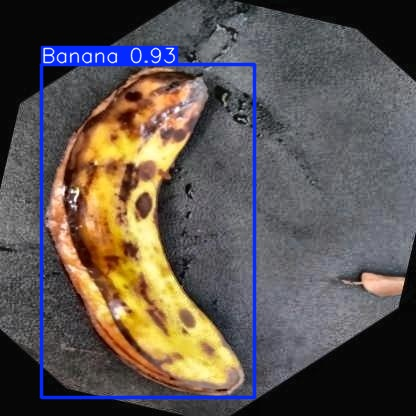

In [ ]:
from IPython.display import Image,display
display(Image(filename="/content/runs/detect/predict/musa-acuminata-banana-8b4f22e4-394a-11ec-9d08-d8c4975e38aa_jpg.rf.525ac85c7ba8db70ab8caafd4c6f3969.jpg"))

# **Counting**

In [ ]:
results = model.predict("/content/test/images/musa-acuminata-banana-ae97e29d-394a-11ec-8a89-d8c4975e38aa_jpg.rf.78b54a71e15c2ec83700fd415362bce5.jpg")
count = len(results[0].boxes)
print("Number of bananas detected:",count)


image 1/1 /content/test/images/musa-acuminata-banana-ae97e29d-394a-11ec-8a89-d8c4975e38aa_jpg.rf.78b54a71e15c2ec83700fd415362bce5.jpg: 416x416 1 Banana, 14.6ms
Speed: 3.5ms preprocess, 14.6ms inference, 1.9ms postprocess per image at shape (1, 3, 416, 416)
Number of bananas detected: 1
